<a href="https://colab.research.google.com/github/BintangPancahaya/PCVK26_06_BintangPP/blob/main/Week7_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##D. TUGAS PRAKTIKUM
###D1. Tugas Individu

**1. Buka Google Colab, hubungkan dengan GitHub, pilih repository praktikum minggu lalu, lalu rename file menjadi `Week7_06.ipynb`.**

Kemudian import (mount) folder yang ada di Google Drive.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**2. Import beberapa library yang akan digunakan**

In [2]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

In [3]:
# Lokasi folder citra praktikum di Google Drive
folder = '/content/drive/MyDrive/PCVK/Pertemuan 7/'

**3. Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV), dengan threshold = 200, secara manual.**

Ketentuan:

| Jenis Global Threshold | Jika nilai piksel > thresh | Jika nilai piksel ≤ thresh |
|---|---|---|
| BINARY | Menjadi nilai maksimal | Menjadi 0 |
| BINARY_INV | Menjadi 0 | Menjadi nilai maksimal |
| TRUNC | Menjadi thresh | Nilai asli tetap |
| TOZERO | Nilai asli tetap | Menjadi 0 |
| TOZERO_INV | Menjadi 0 | Nilai asli tetap |

Ukuran citra : (540, 960)
Intensitas   : 0 sampai 255


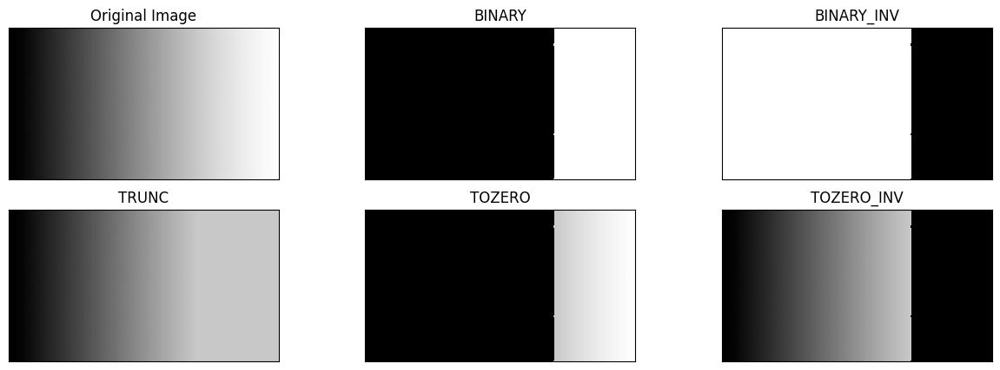

In [6]:
filename = folder + 'gradient.jpg'
img = cv.imread(filename, 0)     # dibaca sebagai grayscale
thresh = 200                     # nilai threshold yang ditentukan
maxval = 255                     # nilai maksimal

print('Ukuran citra :', img.shape)
print('Intensitas   :', img.min(), 'sampai', img.max())

#1. BINARY     : piksel > thresh menjadi maxval, selain itu 0
thresh1 = np.where(img > thresh, maxval, 0).astype(np.uint8)

#2. BINARY_INV : piksel > thresh menjadi 0, selain itu maxval
thresh2 = np.where(img > thresh, 0, maxval).astype(np.uint8)

#3. TRUNC      : piksel > thresh menjadi thresh, selain itu nilai asli tetap
thresh3 = np.where(img > thresh, thresh, img).astype(np.uint8)

#4. TOZERO     : piksel > thresh nilai asli tetap, selain itu 0
thresh4 = np.where(img > thresh, img, 0).astype(np.uint8)

#5. TOZERO_INV : piksel > thresh menjadi 0, selain itu nilai asli tetap
thresh5 = np.where(img > thresh, 0, img).astype(np.uint8)

titles = ['Original Image','BINARY','BINARY_INV','TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize = (15,5))
for i in range(len(images)):
  # vmin=0, vmax=255 agar skala abu-abu tidak di-stretch otomatis (penting untuk TRUNC)
  plt.subplot(2,3,i+1),plt.imshow(images[i],'gray', vmin=0, vmax=255, interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

**4. Buat program Adaptive Threshold: adaptive mean dan adaptive Gaussian tanpa menggunakan `cv.threshold()`, `cv.adaptiveThreshold()`, maupun fungsi filter siap pakai, dengan citra Sudoku yang memiliki pencahayaan tidak merata.**

Ketentuan: global threshold secara manual dengan ambang **127**, ukuran jendela **11 × 11**, **C = 2**, dan **sigma = 2** untuk Gaussian.

Ukuran citra : (423, 419)


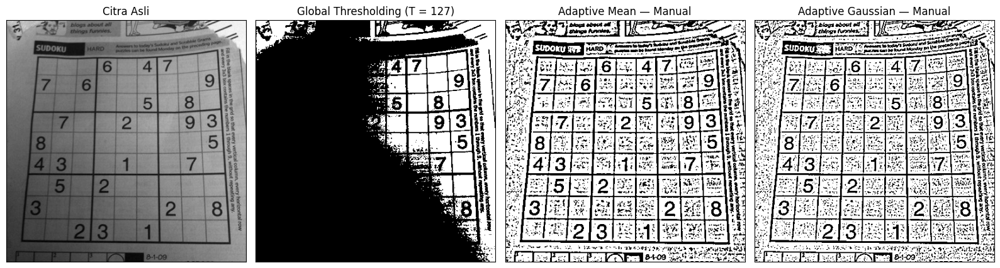

In [8]:
filename = folder + 'sudoku-original.jpg'
gray = cv.imread(filename, 0)    # grayscale

thresh = 127       # ambang global
blockSize = 11     # ukuran jendela 11 x 11
C = 2              # konstanta pengurang
sigma = 2          # sigma untuk Gaussian

print('Ukuran citra :', gray.shape)

th1 = np.where(gray > thresh, 255, 0).astype(np.uint8)

def kernel_rata2(ukuran):
    # semua bobot sama: 1 / (ukuran x ukuran)
    return np.ones((ukuran, ukuran), dtype=np.float64) / (ukuran * ukuran)

def kernel_gaussian(ukuran, sigma):
    r = ukuran // 2
    x = np.arange(-r, r + 1)
    xx, yy = np.meshgrid(x, x)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return kernel / kernel.sum()          # normalisasi agar jumlah bobot = 1

def konvolusi_manual(citra, kernel):
    H, W = citra.shape
    k = kernel.shape[0]
    pad = k // 2
    # padding dengan menyalin piksel pinggir (replicate)
    padded = np.pad(citra.astype(np.float64), pad, mode='edge')
    hasil = np.zeros((H, W), dtype=np.float64)
    # jumlahkan (bobot kernel x citra yang digeser) untuk setiap posisi di jendela
    for i in range(k):
        for j in range(k):
            hasil += kernel[i, j] * padded[i:i + H, j:j + W]
    return hasil

rata2_lokal = np.round(konvolusi_manual(gray, kernel_rata2(blockSize)))
T_mean = rata2_lokal - C
th2 = np.where(gray > T_mean, 255, 0).astype(np.uint8)

rata2_gaussian = np.round(konvolusi_manual(gray, kernel_gaussian(blockSize, sigma)))
T_gaussian = rata2_gaussian - C
th3 = np.where(gray > T_gaussian, 255, 0).astype(np.uint8)

titles = ['Citra Asli', 'Global Thresholding (T = 127)',
          'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize = (16,5))
for i in range(len(citra2)):
    plt.subplot(1,4,i+1),plt.imshow(citra2[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.tight_layout()
plt.show()

**5. A. Buat Otsu Thresholding tanpa menggunakan Library. Tampilkan juga nilai threshold saat menggunakan Otsu's (gunakan image `lena_gs_lc2.jpg` untuk dibandingkan dengan hasil dengan penggunaan library).**

Langkah 1: siapkan citra `lena_gs_lc2.jpg`. File ini tidak ada di folder Pertemuan 7, jadi dibuat dari `lena.jpg` sesuai keterangan di modul, yaitu citra Lena *grayscale low contrast* dengan rentang intensitas 85 sampai 108 (24 level). Caranya: citra diubah ke grayscale, intensitas 0–255 dipetakan secara linear ke 85–108.

In [12]:
lena = cv.imread(folder + 'lena.jpg', 0)                       # Lena grayscale (0-255)
lena_lc = np.round(85 + lena.astype(np.float64) * (108 - 85) / 255).astype(np.uint8)
cv.imwrite(folder + 'lena_gs_lc2.jpg', lena_lc, [cv.IMWRITE_JPEG_QUALITY, 100])

print('Intensitas lena.jpg (grayscale) :', lena.min(), 'sampai', lena.max())
print('Intensitas lena_gs_lc2.jpg      :', lena_lc.min(), 'sampai', lena_lc.max(),
      '(' + str(len(np.unique(lena_lc))) + ' level)')

Intensitas lena.jpg (grayscale) : 0 sampai 255
Intensitas lena_gs_lc2.jpg      : 85 sampai 108 (24 level)


Langkah 2: baca `lena_gs_lc2.jpg` lalu haluskan dengan Gaussian blur.

In [13]:
filename = (folder + 'lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

Langkah 3: fungsi Otsu tanpa library (kode dari modul). Ada dua koreksi kecil yang ditandai komentar `# koreksi`:

1. Nilai `t` yang membuat salah satu kelas kosong dilewati, supaya tidak terjadi pembagian dengan nol (*RuntimeWarning*).
2. Saat pencarian, kelas foreground adalah piksel **≥ t** (`his[t:]`). Kode asli memakai `gray > final_thresh` dan `gray < final_thresh`, sehingga piksel yang nilainya tepat sama dengan threshold tidak ikut diubah dan tetap abu-abu. Karena itu baris pertama diganti menjadi `>=`.

In [14]:
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:      # koreksi: lewati t yang membuat salah satu kelas kosong
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray >= final_thresh] = 255   # koreksi: '>' diganti '>=' (kelas foreground = piksel >= t)
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

In [15]:
otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

96


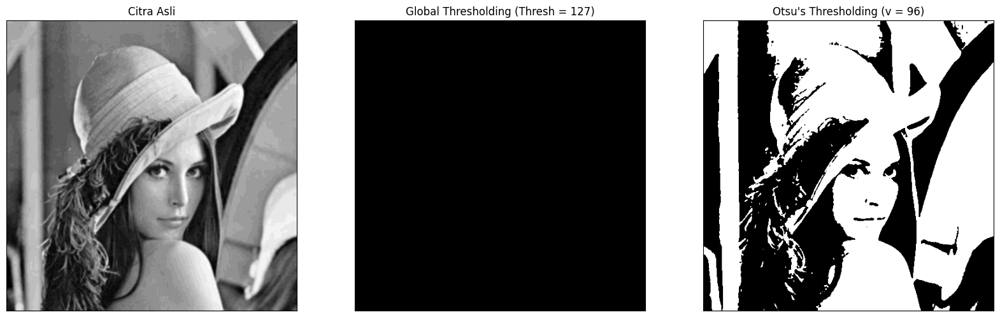

In [16]:
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

Langkah 6: Otsu Thresholding dengan library OpenCV (`cv.THRESH_OTSU`) sebagai pembanding (kode dari modul bagian C.5).

In [17]:
# Dengan Library
filename = (folder + 'lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh = 127

ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)
ret2,th2 = cv.threshold(blur,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)

Langkah 7: tampilkan histogram dan hasil Otsu dengan library.

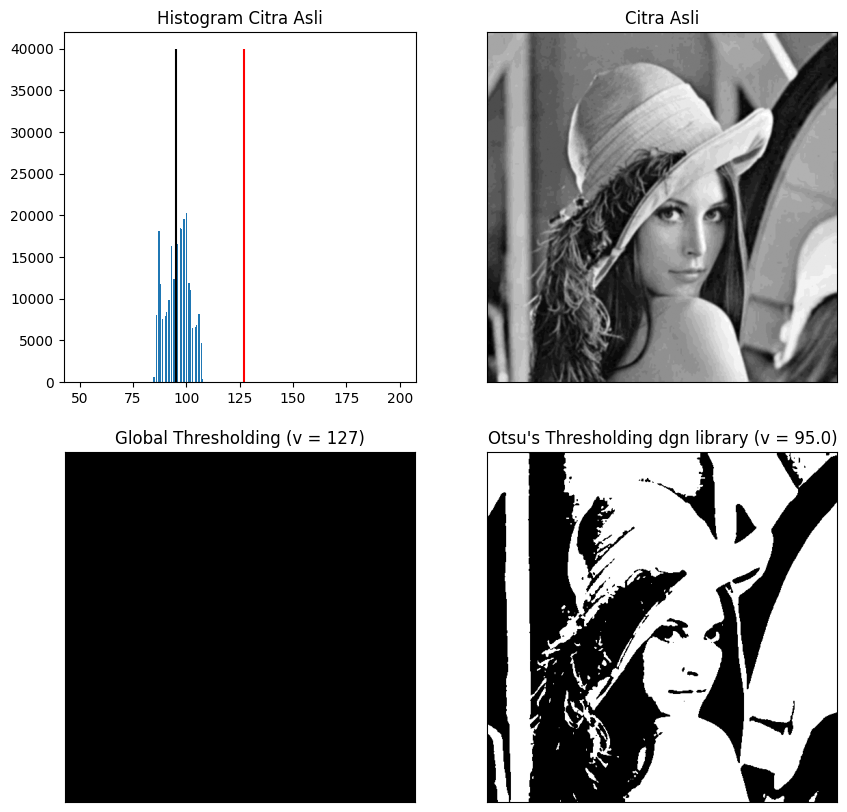

In [18]:
x = ("Otsu's Thresholding dgn library (v = ")+str(ret2)+")"
titles = ['Citra Asli', 'Global Thresholding (v = 127)', x]
citra3 = [blur, th1, th2]

plt.figure(figsize = (10,10))
plt.subplot(2,2,1),plt.hist(blur.ravel(),256,range=[50,200])
plt.vlines(ret,0,40000,colors='red') #garis vertikal merah menunjukan threshold global 127
plt.vlines(ret2,0,40000,colors='black') #garis vertikal hitam menunjukkan threshold hasil otsu's
plt.title('Histogram Citra Asli')
for i in range(len(citra3)):
 plt.subplot(2,2,i+2),plt.imshow(citra3[i],'gray')
 plt.title(titles[i])
 plt.xticks([]),plt.yticks([])
plt.show()

Langkah 8: bandingkan hasil Otsu manual dengan Otsu library.

In [19]:
print('Threshold Otsu manual  :', otsu_thresh, '-> foreground = piksel >=', otsu_thresh)
print('Threshold Otsu library :', ret2, '-> foreground = piksel >', int(ret2))
print('Jumlah piksel berbeda  :', np.sum(otsu_biner != th2), 'dari', blur.size, 'piksel')

Threshold Otsu manual  : 96 -> foreground = piksel >= 96
Threshold Otsu library : 95.0 -> foreground = piksel > 95
Jumlah piksel berbeda  : 0 dari 262144 piksel


**Pertanyaan:** Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam semua? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas (Thresh) supaya gambar Lena ini masih terlihat?


Intensitas minimum citra : 85
Intensitas maksimum citra: 108
Jumlah piksel > 127      : 0


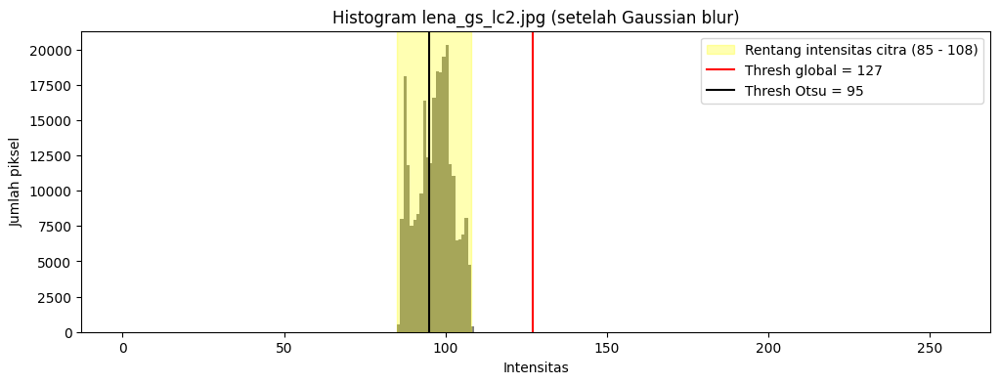

In [20]:
print('Intensitas minimum citra :', blur.min())
print('Intensitas maksimum citra:', blur.max())
print('Jumlah piksel > 127      :', np.sum(blur > 127))

# Histogram dengan garis threshold global 127 dan threshold Otsu
plt.figure(figsize=(12, 4))
plt.hist(blur.ravel(), 256, range=[0, 256], color='gray')
plt.axvspan(blur.min(), blur.max(), color='yellow', alpha=0.3, label='Rentang intensitas citra (%d - %d)' % (blur.min(), blur.max()))
plt.axvline(127, color='red', label='Thresh global = 127')
plt.axvline(ret2, color='black', label="Thresh Otsu = %d" % ret2)
plt.title('Histogram lena_gs_lc2.jpg (setelah Gaussian blur)')
plt.xlabel('Intensitas'), plt.ylabel('Jumlah piksel')
plt.legend()
plt.show()

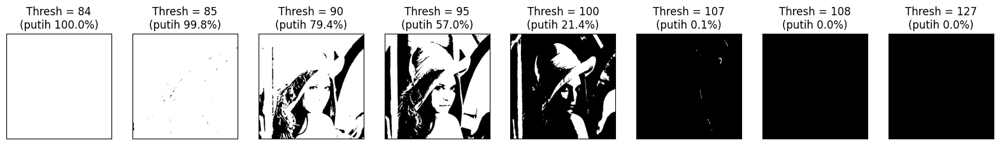

In [21]:
# Mencoba beberapa nilai threshold
daftar_thresh = [84, 85, 90, int(ret2), 100, 107, 108, 127]

plt.figure(figsize=(20, 5))
for i, T in enumerate(daftar_thresh):
    hasil = np.where(blur > T, 255, 0).astype(np.uint8)
    persen_putih = 100 * np.mean(hasil == 255)
    plt.subplot(1, len(daftar_thresh), i + 1)
    plt.imshow(hasil, 'gray', vmin=0, vmax=255)
    plt.title('Thresh = %d\n(putih %.1f%%)' % (T, persen_putih))
    plt.xticks([]), plt.yticks([])
plt.show()

**Jawaban:**

1. **Kenapa hasilnya hitam semua (dilihat dari histogram).** `lena_gs_lc2.jpg` adalah citra *low contrast*. Histogramnya menunjukkan semua piksel berkumpul di rentang sempit **85 sampai 108** (area kuning), dan tidak ada piksel yang bernilai di atas 108. Binary threshold memakai aturan: jika piksel > thresh maka 255, selain itu 0. Garis merah (thresh = 127) berada **di sebelah kanan semua batang histogram**, artinya semua piksel ≤ 127 sehingga semuanya diubah menjadi 0 (jumlah piksel > 127 = 0). Hasilnya citra hitam total.

2. **Ambang supaya Lena masih terlihat.** Thresh harus diletakkan **di dalam rentang intensitas citra** supaya histogram terbelah menjadi dua kelompok (sebagian hitam, sebagian putih):
   - thresh ≥ 108: semua piksel ≤ thresh, hasilnya hitam semua (sama seperti thresh 127).
   - thresh ≤ 84: semua piksel > thresh, hasilnya putih semua.
   - Di ujung rentang (thresh 85 atau 107) gambar masih hampir satu warna (piksel putih 99,8% dan 0,1%).
   - Lena terlihat jelas pada kisaran **thresh ≈ 90 sampai 100** (piksel putih 79,4% sampai 21,4%), dan paling seimbang pada nilai Otsu **thresh = 95** (library; versi manual 96 dengan pembagian kelas yang sama). Nilai ini membelah histogram di lembah antara dua kelompok intensitas sehingga wajah, topi, dan latar Lena terpisah dengan baik.

**5. B. Coba dengan image KTP agar terlihat beda antara hasil Otsu's dengan global threshold biasa.**

Citra yang dipakai adalah `ktp_fulan.jpg` dari folder praktikum (bisa diganti dengan nama file KTP sendiri). Fungsi `otsu()` yang dipakai sama dengan bagian A.

Langkah 1: baca citra KTP sebagai grayscale lalu haluskan dengan Gaussian blur.

166


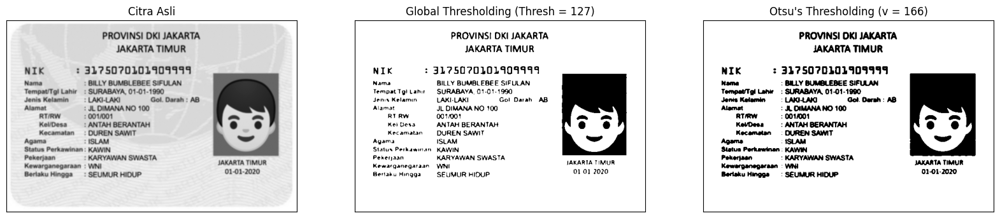

In [22]:
filename = (folder + 'ktp_fulan.jpg')
img_ktp = cv.imread(filename,0)
blur_ktp = cv.GaussianBlur(img_ktp,(5,5),0)
thresh = 127

otsu_biner_ktp, otsu_thresh_ktp = otsu(blur_ktp)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh_ktp)+")"
ret,th1_ktp = cv.threshold(blur_ktp,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra_ktp = [blur_ktp, th1_ktp, otsu_biner_ktp]

plt.figure(figsize = (20,15))
for i in range(len(citra_ktp)):
    plt.subplot(1,3,i+1),plt.imshow(citra_ktp[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

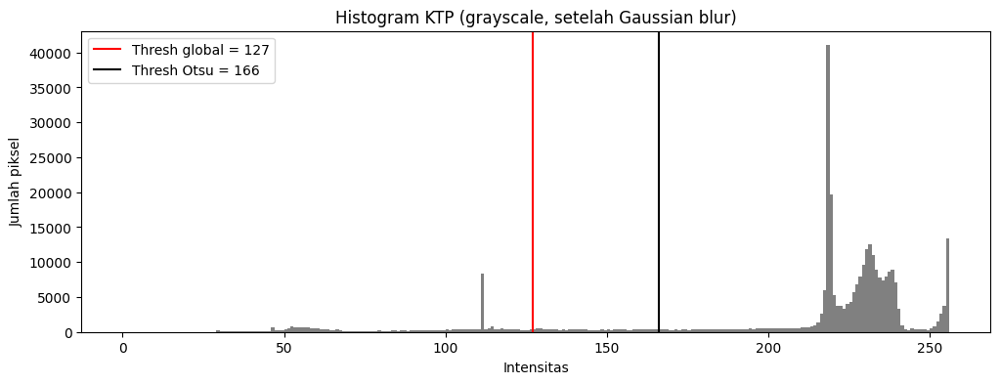

Persentase piksel hitam (global 127) : 11.5%
Persentase piksel hitam (Otsu 166)    : 15.7%


In [24]:
# Membandingkan dengan ktp_fulan
plt.figure(figsize=(12, 4))
plt.hist(blur_ktp.ravel(), 256, range=[0, 256], color='gray')
plt.axvline(thresh, color='red', label='Thresh global = %d' % thresh)
plt.axvline(otsu_thresh_ktp, color='black', label="Thresh Otsu = %d" % otsu_thresh_ktp)
plt.title('Histogram KTP (grayscale, setelah Gaussian blur)')
plt.xlabel('Intensitas'), plt.ylabel('Jumlah piksel')
plt.legend()
plt.show()

print('Persentase piksel hitam (global 127) : %.1f%%' % (100 * np.mean(th1_ktp == 0)))
print('Persentase piksel hitam (Otsu %d)    : %.1f%%' % (otsu_thresh_ktp, 100 * np.mean(otsu_biner_ktp == 0)))

**Perbandingan hasil (KTP_Fulan):**

- **Histogram.** Ada satu puncak besar di kisaran 215–245, yaitu latar biru muda KTP yang menjadi terang setelah diubah ke grayscale. Piksel gelap (teks, foto, dan tepi huruf) tersebar di kisaran 40–160. Otsu memilih **thresh = 166**, tepat di lembah sebelum puncak latar, sedangkan thresh 127 berada di tengah sebaran piksel gelap.
- **Global threshold (127).** Latar menjadi putih bersih, tetapi piksel tepi huruf yang bernilainya di antara 127 dan 166 ikut menjadi putih. Akibatnya huruf menjadi tipis dan beberapa karakter kecil hilang: tanda titik dua sebelum isian data, garis miring pada "Tempat/Tgl Lahir", "RT/RW", "Kel/Desa", tanda "-" pada "01-01-2020", serta titik dan titik dua pada "Gol. Darah : AB". Piksel hitam hanya 11,5%.
- **Otsu (166).** Semua piksel teks beserta tepinya menjadi hitam, sehingga tulisan tebal dan lengkap (tanda baca kecil tetap muncul). Kekurangannya, pada huruf yang kecil beberapa huruf jadi sedikit menempel. Foto berlatar merah menjadi kotak hitam penuh. Piksel hitam 15,7%.
- **Kesimpulan.** Otsu menentukan ambang secara otomatis dari bentuk histogram, sehingga pemisahan teks dan latar KTP lebih lengkap dibanding thresh 127 yang ditentukan tanpa melihat histogram.

**6. A. Lakukan Segmentasi Berbasis Region (Region Growing) pada citra `data.coins()` dari skimage.**

Ketentuan:
- Tentukan 3 seed: satu di dalam koin, satu di latar, dan satu tepat di tepi koin.
- Jalankan dengan T = 5, 20, dan 60.
- Tampilkan hasilnya dalam grid 3×3 (seed × T).

Langkah 1: baca citra coins. Citra dihaluskan dulu dengan Gaussian (sigma = 2) supaya tekstur ukiran pada koin tidak menghentikan pertumbuhan region terlalu cepat.

In [30]:
  img = data.coins()          # grayscale, 303 x 384
img_halus = gaussian(img, sigma=2, preserve_range=True)

print('Ukuran citra coins :', img.shape)
print('Intensitas         :', img.min(), 'sampai', img.max())

Ukuran citra coins : (303, 384)
Intensitas         : 1 sampai 252


Seed Dalam koin (baris, kolom): (54, 44) | intensitas asli: 194 | setelah Gaussian: 175.48
Seed Latar      (baris, kolom): (90, 75) | intensitas asli: 93 | setelah Gaussian: 92.88
Seed Tepi koin  (baris, kolom): (54, 22) | intensitas asli: 151 | setelah Gaussian: 144.43


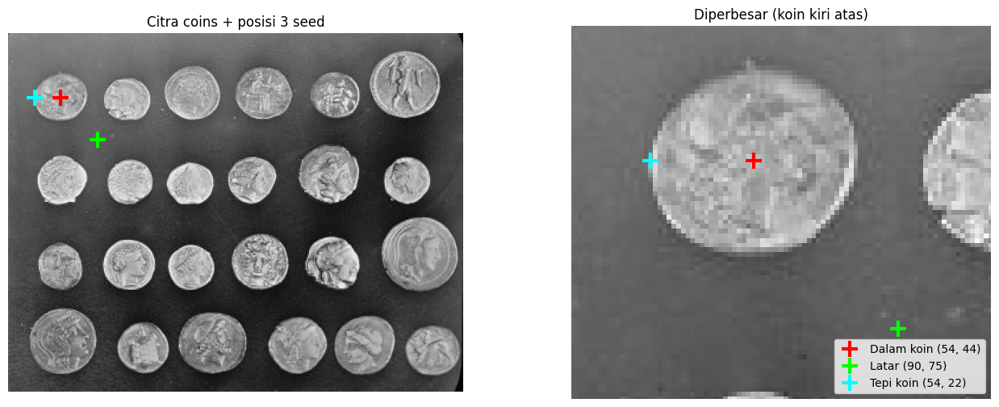

In [31]:
seeds = {
    'Dalam koin': (54, 44),
    'Latar'     : (90, 75),
    'Tepi koin' : (54, 22),
}
nilai_T = [5, 20, 60]
warna_seed = ['red', 'lime', 'cyan']

for nama, posisi in seeds.items():
    print('Seed %-10s (baris, kolom): %s | intensitas asli: %d | setelah Gaussian: %.2f'
          % (nama, posisi, img[posisi], img_halus[posisi]))

fig, axs = plt.subplots(1, 2, figsize=(16, 6))
axs[0].imshow(img, cmap='gray')
axs[0].set_title('Citra coins + posisi 3 seed')
axs[1].imshow(img, cmap='gray')
axs[1].set_xlim(5, 95), axs[1].set_ylim(105, 25)          # perbesar area koin kiri atas
axs[1].set_title('Diperbesar (koin kiri atas)')
for ax in axs:
    for (nama, (r, c)), w in zip(seeds.items(), warna_seed):
        ax.plot(c, r, '+', color=w, markersize=15, markeredgewidth=3, label='%s (%d, %d)' % (nama, r, c))
    ax.axis('off')
axs[1].legend(loc='lower right')
plt.show()

In [32]:
def region_growing(citra, seed, T):
    H, W = citra.shape
    mask = np.zeros((H, W), dtype=bool)
    mask[seed] = True
    jumlah_intensitas = float(citra[seed])   # untuk menghitung rata-rata region
    n = 1                                    # banyak piksel di dalam region
    antrean = deque([seed])
    tetangga = [(-1, -1), (-1, 0), (-1, 1),
                ( 0, -1),          ( 0, 1),
                ( 1, -1), ( 1, 0), ( 1, 1)]

    while antrean:
        y, x = antrean.popleft()
        for dy, dx in tetangga:
            ny, nx = y + dy, x + dx
            if 0 <= ny < H and 0 <= nx < W and not mask[ny, nx]:
                rata2_region = jumlah_intensitas / n
                if abs(citra[ny, nx] - rata2_region) < T:
                    mask[ny, nx] = True
                    jumlah_intensitas += citra[ny, nx]
                    n += 1
                    antrean.append((ny, nx))
    return mask

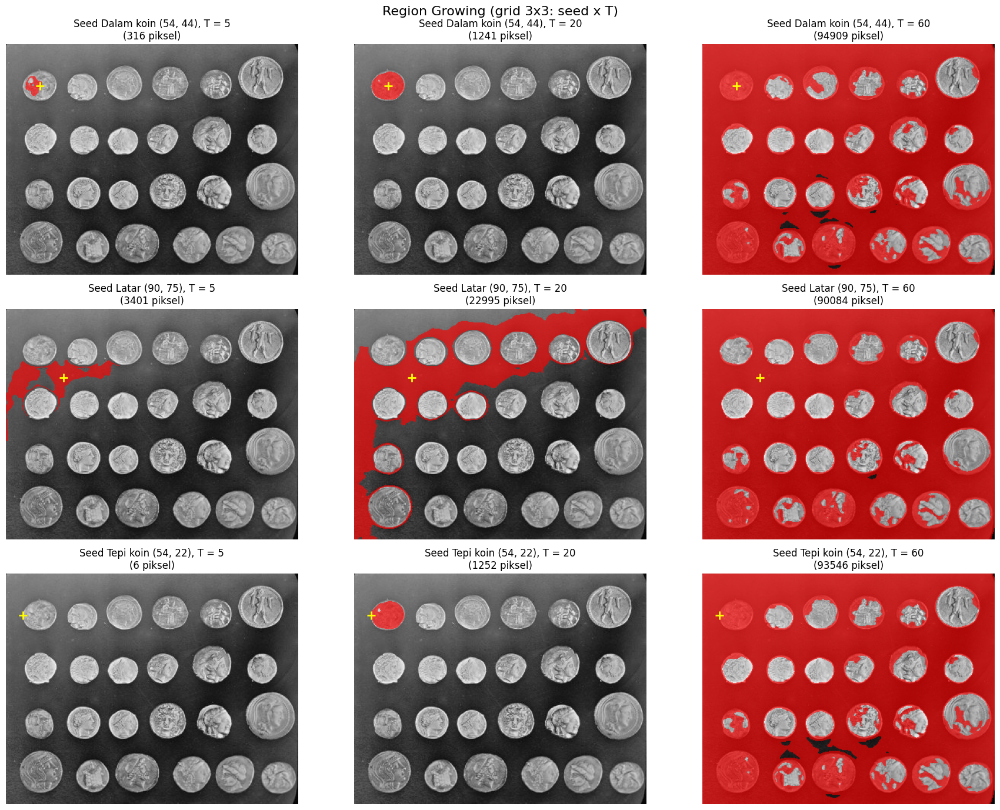

In [33]:
jumlah_piksel = pd.DataFrame(index=list(seeds.keys()), columns=['T = %d' % T for T in nilai_T])

fig, axs = plt.subplots(3, 3, figsize=(18, 14))
for i, (nama, posisi) in enumerate(seeds.items()):
    for j, T in enumerate(nilai_T):
        mask = region_growing(img_halus, posisi, T)
        jumlah_piksel.loc[nama, 'T = %d' % T] = int(mask.sum())

        tampilan = np.stack([img, img, img], axis=-1).astype(np.float64)
        tampilan[mask] = 0.35 * tampilan[mask] + 0.65 * np.array([255, 0, 0])   # region diberi warna merah
        axs[i, j].imshow(tampilan.astype(np.uint8))
        axs[i, j].plot(posisi[1], posisi[0], '+', color='yellow', markersize=10, markeredgewidth=2)
        axs[i, j].set_title('Seed %s %s, T = %d\n(%d piksel)' % (nama, posisi, T, mask.sum()))
        axs[i, j].axis('off')
plt.suptitle('Region Growing (grid 3x3: seed x T)', fontsize=16)
plt.tight_layout()
plt.show()

**6. B. Gunakan `skimage.segmentation.flood()`.** Fungsi ini menghasilkan mask region dari seed dengan menerima piksel yang terhubung dan intensitasnya berada dalam toleransi terhadap intensitas seed.

Langkah 1.

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

gray = data.coins()
seed = (121, 63)          # (baris, kolom)

# Segmentasi menggunakan fungsi siap pakai
region = flood(
    gray,
    seed_point=seed,
    tolerance=20,
    connectivity=1       # 4 tetangga untuk citra 2D
)

In [35]:
print('Hasil kode modul -> seed', seed, '| tolerance 20 :', np.sum(region), 'piksel')

Hasil kode modul -> seed (121, 63) | tolerance 20 : 177 piksel


In [36]:
seed_flood = (36, 43)     # (baris, kolom)
print('Seed (baris, kolom): %s | intensitas: %f' % (seed_flood, gray[seed_flood]))

hasil_flood = {}
for T in nilai_T:
    hasil_flood[T] = flood(gray, seed_point=seed_flood, tolerance=T, connectivity=1)
    print('Toleransi %2d: %d piksel' % (T, np.sum(hasil_flood[T])))

Seed (baris, kolom): (36, 43) | intensitas: 159.000000
Toleransi  5: 21 piksel
Toleransi 20: 919 piksel
Toleransi 60: 15253 piksel


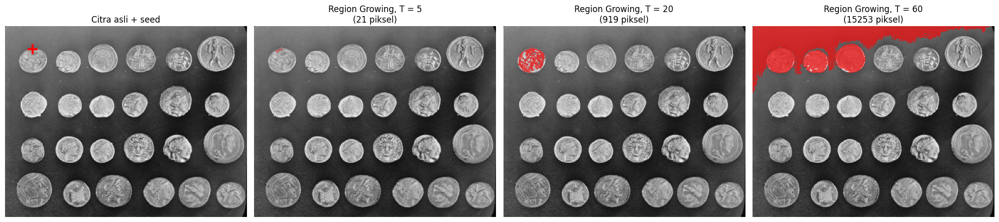

In [37]:
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
axs[0].imshow(gray, cmap='gray')
axs[0].plot(seed_flood[1], seed_flood[0], 'r+', markersize=15, markeredgewidth=3)
axs[0].set_title('Citra asli + seed')
axs[0].axis('off')

for i, T in enumerate(nilai_T):
    tampilan = np.stack([gray, gray, gray], axis=-1).astype(np.float64)
    tampilan[hasil_flood[T]] = 0.35 * tampilan[hasil_flood[T]] + 0.65 * np.array([255, 0, 0])
    axs[i + 1].imshow(tampilan.astype(np.uint8))
    axs[i + 1].set_title('Region Growing, T = %d\n(%d piksel)' % (T, np.sum(hasil_flood[T])))
    axs[i + 1].axis('off')
plt.tight_layout()
plt.show()

**7. Lakukan segmentasi warna pada image `ktp_fulan.jpg`, munculkan hanya warna yang biru saja** (petunjuk: gunakan K-Means untuk menampilkan hanya warna tertentu saja).

Rentang biru muda kebiruan pada latar KTP (dengan warna HSV):
`kelompok_biru = np.where( (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40) )`

In [38]:
import cv2
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Baca citra dan ubah ke RGB
filename = (folder + 'ktp_fulan.jpg')

img = cv.imread(filename)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Ubah citra menjadi array 2D (piksel)
Z = img.reshape((-1, 3))
Z = np.float32(Z)

In [39]:
# Tentukan jumlah cluster
k = 8
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)

# Dapatkan label dan pusat cluster
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
# Bentuk citra hasil segmentasi
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

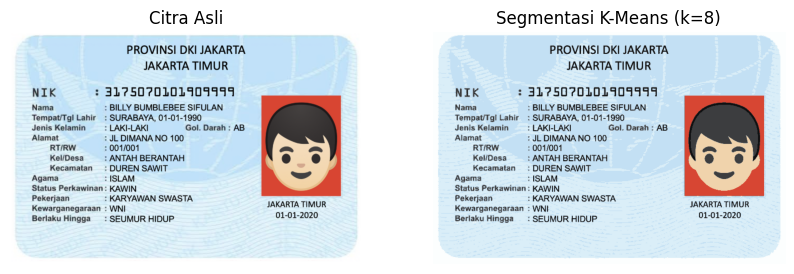

In [40]:
# Tampilkan hasil
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(segmented_img)
plt.title('Segmentasi K-Means (k=' + str(k) + ')')
plt.axis('off')
plt.show()

In [41]:
centers_hsv = cv.cvtColor(centers.reshape(1, k, 3), cv.COLOR_RGB2HSV).reshape(k, 3)
H = centers_hsv[:, 0].astype(int)
S = centers_hsv[:, 1].astype(int)
V = centers_hsv[:, 2].astype(int)

# Rentang biru muda kebiruan pada latar KTP
kelompok_biru = np.where( (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40) )
print('Cluster yang termasuk warna biru:', kelompok_biru[0])

tabel_cluster = pd.DataFrame({
    'R': centers[:, 0], 'G': centers[:, 1], 'B': centers[:, 2],
    'H': H, 'S': S, 'V': V,
    'Jumlah piksel': np.bincount(labels, minlength=k),
    'Biru?': ['Ya' if i in kelompok_biru[0] else 'Tidak' for i in range(k)],
})
tabel_cluster.index.name = 'Cluster'
tabel_cluster

Cluster yang termasuk warna biru: [1 4 7]


,R,G,B,H,S,V,Jumlah piksel,Biru?
Cluster,,,,,,,,
0,60,61,63,110,12,63,16966,Tidak
1,218,238,248,100,31,248,123331,Ya
2,215,70,51,3,195,215,10912,Tidak
3,15,16,17,105,30,17,8526,Tidak
4,138,149,157,103,31,157,9341,Ya
5,240,211,172,17,72,240,8799,Tidak
6,252,254,254,90,2,254,25242,Tidak
7,195,224,244,102,51,244,114735,Ya


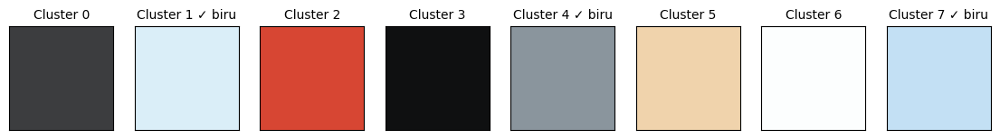

In [42]:
plt.figure(figsize=(14, 2.2))
for i in range(k):
    plt.subplot(1, k, i + 1)
    plt.imshow(np.full((10, 10, 3), centers[i], dtype=np.uint8))
    tanda = ' ✓ biru' if i in kelompok_biru[0] else ''
    plt.title('Cluster %d%s' % (i, tanda), fontsize=10)
    plt.xticks([]), plt.yticks([])
plt.show()

In [43]:
mask_biru = np.isin(labels, kelompok_biru[0]).reshape(img.shape[:2])

hanya_biru = np.zeros_like(img)
hanya_biru[mask_biru] = img[mask_biru]

print('Persentase piksel biru: %.1f%%' % (100 * mask_biru.mean()))

Persentase piksel biru: 77.8%


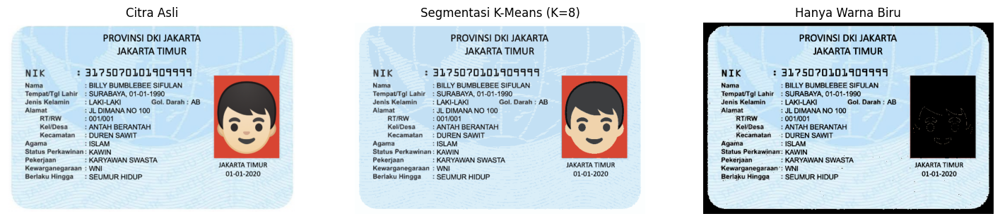

In [44]:
plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1), plt.imshow(img), plt.title('Citra Asli'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(segmented_img), plt.title('Segmentasi K-Means (K=' + str(k) + ')'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(hanya_biru), plt.title('Hanya Warna Biru'), plt.axis('off')
plt.show()

In [2]:
# Instalasi Tesseract OCR
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [26]:
import pytesseract
from pytesseract import Output

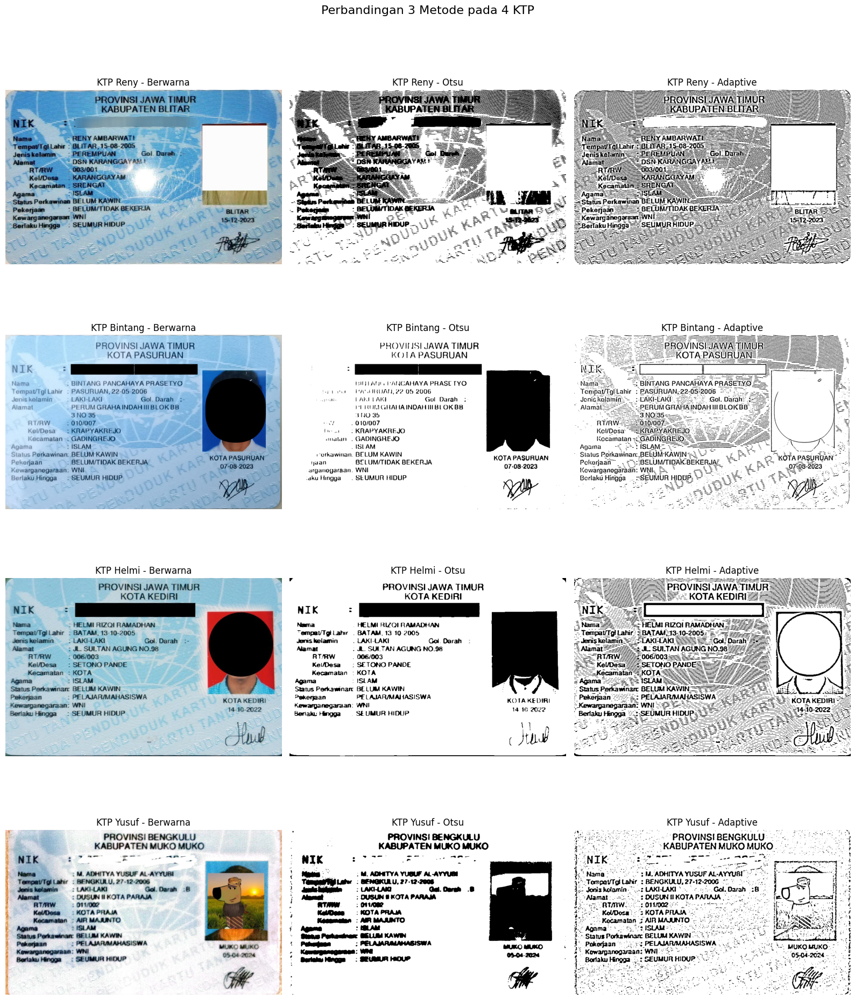

In [30]:
# Daftar nama pemilik KTP sesuai dengan penamaan file Anda
daftar_nama = ['reny', 'bintang', 'helmi', 'yusuf']
judul = ['Berwarna', 'Otsu', 'Adaptive']

# Membuat figure matplotlib dengan grid 4 baris dan 3 kolom
# Ukuran disesuaikan agar gambar tidak terlalu kecil
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(16, 20))
fig.suptitle('Perbandingan 3 Metode pada 4 KTP', fontsize=16)

# Loop untuk setiap nama KTP
for baris, nama in enumerate(daftar_nama):
    # Sesuaikan path direktori dengan path Google Drive Anda
    path_gambar = f'/content/drive/MyDrive/PCVK/Pertemuan 7/ktp_{nama}.jpg'

    # Membaca citra
    ktp = cv.imread(path_gambar)

    if ktp is None:
        print(f"Peringatan: Gambar untuk {nama} tidak ditemukan di path: {path_gambar}")
        continue

    # Proses konversi dan filter (Sama seperti kode asli)
    gray_ktp = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)
    blur_ktp = cv.GaussianBlur(gray_ktp, (3, 3), 0)

    # Thresholding
    ret, citra_otsu = cv.threshold(blur_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    citra_adaptive = cv.adaptiveThreshold(blur_ktp, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                          cv.THRESH_BINARY, 25, 10)

    # List citra yang akan ditampilkan
    citra_uji = [cv.cvtColor(ktp, cv.COLOR_BGR2RGB), citra_otsu, citra_adaptive]

    # Menampilkan 3 variasi gambar untuk 1 KTP pada baris yang sesuai
    for kolom in range(3):
        ax = axes[baris, kolom]
        cmap = None if kolom == 0 else 'gray'
        ax.imshow(citra_uji[kolom], cmap=cmap)
        # Menambahkan nama orang pada judul setiap gambar
        ax.set_title(f"KTP {nama.capitalize()} - {judul[kolom]}")
        ax.axis('off')

# Merapikan tata letak agar tidak berdempetan
plt.tight_layout()
plt.subplots_adjust(top=0.95) # Memberi ruang untuk suptitle
plt.show()

In [32]:
# ----- Langkah 2: pembacaan teks dengan pytesseract.image_to_string() -----
konfigurasi = '--psm 6'
bahasa = 'ind'

# Tentukan ulang daftar nama dan judul
daftar_nama = ['reny', 'bintang', 'helmi', 'yusuf']
judul = ['Berwarna', 'Otsu', 'Adaptive']

# Menggunakan dictionary bersarang (nested dictionary) untuk menyimpan semua hasil
hasil_teks = {}

for pemilik in daftar_nama:
    print(f"\n{'#'*15} MEMBACA OCR KTP: {pemilik.upper()} {'#'*15}\n")

    # 1. Kita perlu memproses ulang gambarnya di sini agar citra_uji diperbarui untuk tiap orang
    path_gambar = f'/content/drive/MyDrive/PCVK/Pertemuan 7/ktp_{pemilik}.jpg'
    ktp = cv.imread(path_gambar)

    if ktp is None:
        continue

    gray_ktp = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)
    blur_ktp = cv.GaussianBlur(gray_ktp, (3, 3), 0)
    _, citra_otsu = cv.threshold(blur_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    citra_adaptive = cv.adaptiveThreshold(blur_ktp, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 25, 10)

    citra_uji = [cv.cvtColor(ktp, cv.COLOR_BGR2RGB), citra_otsu, citra_adaptive]

    # 2. Proses OCR untuk ke-3 metode (Berwarna, Otsu, Adaptive)
    hasil_teks[pemilik] = {} # Buat sub-dictionary untuk menyimpan teks per orang

    for nama_metode, citra in zip(judul, citra_uji):
        teks = pytesseract.image_to_string(citra, lang=bahasa, config=konfigurasi)
        hasil_teks[pemilik][nama_metode] = teks

        print('=' * 10, f"{nama_metode} - KTP {pemilik.capitalize()}", '=' * 10)
        print(teks)
        print()


############### MEMBACA OCR KTP: RENY ###############

========== Berwarna - KTP Reny ==========
5—cee #1. cw zr -
5Z-—e AAA AA
—:—e-: —5— DAY I NS“ A NYA —- —
5 — ABU AE BE AR
aa Pa ee aa AA
— JP 5 ——— 2 5 — 5
5—.—— —— 3 —————-
— — 5 |—————
— ——— To ——— FP
JT &&L&&& 55 ——
we Pr 5 -
— Nama — — —HENYAMBARWATE- —————— Te
——ws-—————— A5 —.—
STempargi Lahi SBL PFAR 15-03-2005 3 ——
Pa — me wi —
jera — PEREMPUAN ——— Gol Darah —
aa ea aa wwe -
—J5—— — ——ew —
Alama— — “DSN KARANGAY II FF
— AA 930p — 5 —
— RAM 03001 —— A5 PP
—— Kel/Dese —KARANGGAYAM Ea | PF
11 AA ES 5 FA
“Agama SAM — PE FA
A3 5 AA 2 AS
—Status Perkawinan BELUM KAWI-———.-——— 5
Pokana — BELUM DAK BEKERIA 3 ge
“Kewarganegaraan WNI 5 5. 22 2023 —
2Beriaku Hingga - SEUMURHIDUP —— 5. 55
AAA AA
SA — AA AA Le 5 5—ya
SA AK AAA AE
Ae AA 2 EA A
PA BA SP AA
5 ti AA #-w—-——6—-———
SE — RAT ———— “AK KKS Sa ——
AE AA Ae ———ara


========== Otsu - KTP Reny ==========
- en —- —-  £
Ba SUPATENG ,
— -——— ——— AP
FI “ga ————....
—. vw — PP —— aus -


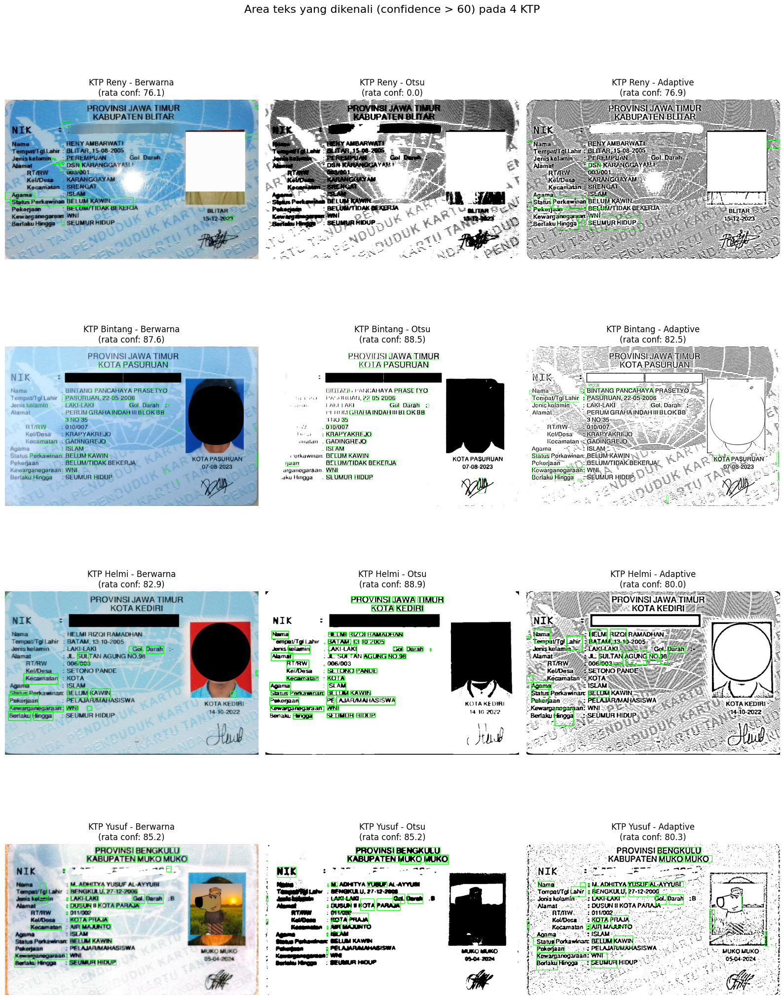

In [33]:
# ----- Langkah 3: tampilkan area teks yang dikenali dengan kotak hijau -----
from pytesseract import Output
import numpy as np

# Fungsi tidak perlu diubah, tetap sama seperti aslinya
def gambar_kotak_teks(citra, berwarna, confidence_min=60):
    data = pytesseract.image_to_data(citra, lang=bahasa, config=konfigurasi, output_type=Output.DICT)

    if berwarna:
        hasil = citra.copy()
    else:
        hasil = cv.cvtColor(citra, cv.COLOR_GRAY2BGR)

    confidence_terpakai = []
    for i in range(len(data['text'])):
        conf = int(float(data['conf'][i])) if data['conf'][i] != '-1' else -1
        if conf > confidence_min and data['text'][i].strip() != '':
            x, y, w, h = data['left'][i], data['top'][i], data['width'][i], data['height'][i]
            cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)
            confidence_terpakai.append(conf)

    return hasil, confidence_terpakai

# --- Bagian yang dimodifikasi untuk 4 KTP ---
batas_confidence = 60
daftar_nama = ['reny', 'bintang', 'helmi', 'yusuf']
judul = ['Berwarna', 'Otsu', 'Adaptive']

# Menyiapkan kanvas 4 baris x 3 kolom
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(16, 22))
fig.suptitle('Area teks yang dikenali (confidence > ' + str(batas_confidence) + ') pada 4 KTP', fontsize=16)

# Looping untuk setiap KTP
for baris, pemilik in enumerate(daftar_nama):
    # Membaca ulang gambar agar data citra sesuai dengan orang yang sedang diproses
    path_gambar = f'/content/drive/MyDrive/PCVK/Pertemuan 7/ktp_{pemilik}.jpg'
    ktp = cv.imread(path_gambar)

    if ktp is None:
        continue

    # Memproses ulang filter untuk KTP saat ini
    gray_ktp = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)
    blur_ktp = cv.GaussianBlur(gray_ktp, (3, 3), 0)
    _, citra_otsu = cv.threshold(blur_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    citra_adaptive = cv.adaptiveThreshold(blur_ktp, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 25, 10)

    citra_uji = [cv.cvtColor(ktp, cv.COLOR_BGR2RGB), citra_otsu, citra_adaptive]

    # Looping untuk ke-3 metode (Berwarna, Otsu, Adaptive)
    for kolom, (nama_metode, citra, berwarna) in enumerate(zip(judul, citra_uji, [True, False, False])):
        # Memperbaiki variabel hardcode 'ktp_reny' menjadi 'ktp' yang sedang diproses
        citra_asli_format = ktp if nama_metode == 'Berwarna' else citra

        kotak, conf_list = gambar_kotak_teks(citra_asli_format, berwarna=(nama_metode == 'Berwarna'), confidence_min=batas_confidence)
        rata_conf = np.mean(conf_list) if len(conf_list) > 0 else 0

        # Menampilkan gambar pada posisi baris dan kolom yang tepat
        ax = axes[baris, kolom]
        ax.imshow(cv.cvtColor(kotak, cv.COLOR_BGR2RGB))
        ax.set_title(f'KTP {pemilik.capitalize()} - {nama_metode}\n(rata conf: {rata_conf:.1f})')
        ax.axis('off')

# Merapikan tata letak gambar
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

In [34]:
import pandas as pd
import numpy as np
import cv2 as cv
import pytesseract
from pytesseract import Output

acuan = [
    'PROVINSI', 'NIK', 'Nama', 'Tempat', 'Jenis Kelamin',
    'Alamat', 'Agama', 'Pekerjaan', 'Kewarganegaraan', 'WNI',
]

def bersihkan(teks):
    return teks.strip().lower()

def cek_kecocokan(daftar_acuan, teks_ocr):
    teks_bersih = bersihkan(teks_ocr)
    hasil = []
    for kata in daftar_acuan:
        cocok = bersihkan(kata) in teks_bersih
        hasil.append(cocok)
    return hasil

# List untuk menyimpan total 12 hasil ringkasan (4 KTP x 3 metode)
ringkasan_global = []

daftar_nama = ['reny', 'bintang', 'helmi', 'yusuf']
judul = ['Berwarna', 'Otsu', 'Adaptive']

# Looping untuk setiap KTP
for pemilik in daftar_nama:
    print(f"\n{'='*20} TABEL KECOCOKAN: KTP {pemilik.upper()} {'='*20}")

    tabel_kecocokan = pd.DataFrame({'Teks sebenarnya': acuan})

    # Membaca ulang citra untuk mengekstrak nilai confidence secara mandiri
    path_gambar = f'/content/drive/MyDrive/PCVK/Pertemuan 7/ktp_{pemilik}.jpg'
    ktp = cv.imread(path_gambar)

    if ktp is None:
        continue

    gray_ktp = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)
    blur_ktp = cv.GaussianBlur(gray_ktp, (3, 3), 0)
    _, citra_otsu = cv.threshold(blur_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    citra_adaptive = cv.adaptiveThreshold(blur_ktp, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 25, 10)

    citra_uji = [ktp, citra_otsu, citra_adaptive]

    # Evaluasi ke-3 metode untuk 1 KTP
    for kolom, (nama_metode, citra) in enumerate(zip(judul, citra_uji)):

        # 1. Mengambil teks hasil OCR dari Langkah 2
        teks_ocr = hasil_teks[pemilik][nama_metode]

        # 2. Mengisi Dataframe Tabel Kecocokan
        kolom_ocr = 'OCR ' + nama_metode
        tabel_kecocokan[kolom_ocr] = cek_kecocokan(acuan, teks_ocr)

        # 3. Menghitung jumlah yang cocok dan persentase
        jumlah_cocok = tabel_kecocokan[kolom_ocr].sum()
        persen = (jumlah_cocok / len(acuan)) * 100

        # 4. Menghitung rata-rata confidence untuk ringkasan
        data_conf = pytesseract.image_to_data(citra, lang=bahasa, config=konfigurasi, output_type=Output.DICT)
        conf_terpakai = [
            int(float(data_conf['conf'][i])) for i in range(len(data_conf['text']))
            if data_conf['conf'][i] != '-1' and int(float(data_conf['conf'][i])) > 60 and data_conf['text'][i].strip() != ''
        ]
        rata_conf = np.mean(conf_terpakai) if len(conf_terpakai) > 0 else 0

        # 5. Memasukkan data ke daftar ringkasan global
        ringkasan_global.append({
            'Pemilik KTP': pemilik.capitalize(),
            'Metode OCR': nama_metode,
            'Item terbaca tepat': jumlah_cocok,
            'Kecocokan (%)': round(persen, 1),
            'Rata-rata conf': round(rata_conf, 1)
        })

    # Menampilkan tabel kecocokan spesifik untuk orang tersebut
    print(tabel_kecocokan)

# Menampilkan tabel ringkasan akhir (12 Baris)
print(f"\n{'='*20} RINGKASAN KESELURUHAN (12 HASIL) {'='*20}")
tabel_ringkasan = pd.DataFrame(ringkasan_global)

# Jika dijalankan di Google Colab/Jupyter, gunakan display() agar tabel lebih rapi
try:
    display(tabel_ringkasan)
except NameError:
    print(tabel_ringkasan)


==================== TABEL KECOCOKAN: KTP RENY ====================
   Teks sebenarnya  OCR Berwarna  OCR Otsu  OCR Adaptive
0         PROVINSI         False     False         False
1              NIK         False     False         False
2             Nama          True     False          True
3           Tempat         False     False         False
4    Jenis Kelamin         False     False         False
5           Alamat         False     False         False
6            Agama          True     False          True
7        Pekerjaan         False     False          True
8  Kewarganegaraan          True     False         False
9              WNI          True     False         False

==================== TABEL KECOCOKAN: KTP BINTANG ====================
   Teks sebenarnya  OCR Berwarna  OCR Otsu  OCR Adaptive
0         PROVINSI          True     False          True
1              NIK         False     False         False
2             Nama         False     False          True
3   

,Pemilik KTP,Metode OCR,Item terbaca tepat,Kecocokan (%),Rata-rata conf
0,Reny,Berwarna,4,40.0,76.1
1,Reny,Otsu,0,0.0,0.0
2,Reny,Adaptive,3,30.0,76.9
3,Bintang,Berwarna,2,20.0,87.6
4,Bintang,Otsu,1,10.0,88.5
5,Bintang,Adaptive,7,70.0,82.5
6,Helmi,Berwarna,6,60.0,82.9
7,Helmi,Otsu,10,100.0,88.9
8,Helmi,Adaptive,3,30.0,80.0
9,Yusuf,Berwarna,3,30.0,85.2


### Pertanyaan

1. **Citra masukan mana yang menghasilkan pembacaan paling tepat?** Lihat kolom "Kecocokan (%)" pada `tabel_ringkasan` — citra dengan angka paling besar adalah yang paling tepat dibaca. Biasanya ini adalah citra **berwarna asli** atau **Adaptive**, karena keduanya menjaga lebih banyak detail halus pada tulisan dibanding Otsu yang kadang menghapus goresan tipis.

2. **Minimal dua kesalahan pembacaan:** lihat hasil cetakan `hasil_teks` pada Langkah 2 dan bandingkan dengan tulisan asli. Contoh pola kesalahan yang umum terjadi pada OCR dokumen: huruf **O tertukar dengan angka 0**, huruf **I tertukar dengan angka 1 atau huruf l**, serta **garis kotak/formulir pada KTP ikut terbaca sebagai karakter aneh** (misalnya `-`, `|`, atau `?`). Tulis dua contoh nyata yang muncul pada hasil OCR-mu.

3. **Apakah segmentasi selalu meningkatkan ketepatan OCR?** **Tidak selalu.** Segmentasi (Otsu/Adaptive) membantu ketika pencahayaan citra asli tidak rata atau latar belakangnya ramai/berwarna, karena keduanya menyederhanakan citra menjadi hitam-putih tegas yang memudahkan Tesseract membedakan huruf dari latar. Namun kalau threshold-nya kurang pas (ambang terlalu ketat atau terlalu longgar), sebagian goresan huruf tipis bisa ikut terhapus atau tulisan tertutup noise, sehingga hasilnya malah **lebih buruk** daripada citra berwarna aslinya. Bandingkan nilai "Kecocokan (%)" pada tabelmu: kalau Otsu/Adaptive tidak selalu lebih tinggi dari Berwarna, itu bukti bahwa segmentasi tidak otomatis meningkatkan ketepatan OCR.

4. **Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?** Latar belakang KTP yang **berpola/bergambar** (seperti foto, logo, atau background bermotif) membuat Tesseract kesulitan membedakan mana yang tulisan dan mana yang bagian gambar, sehingga rawan menghasilkan karakter yang salah atau terlewat. Latar yang **polos dan kontras tinggi dengan warna tulisan** (misalnya tulisan hitam di atas latar putih polos) menghasilkan pembacaan yang jauh lebih bersih.

5. **Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?** Cek `tabel_ringkasan`: bandingkan urutan kolom "Rata-rata confidence" dengan urutan kolom "Kecocokan (%)". **Tidak selalu sejalan** — confidence hanya mengukur seberapa yakin Tesseract terhadap karakter yang **berhasil dikenalinya**, bukan seberapa banyak kata yang benar-benar sesuai aslinya. Bisa saja sebuah metode sangat yakin (confidence tinggi) pada sedikit kata yang terbaca, tapi kata-kata lain yang penting justru terlewat sama sekali (sehingga kecocokannya rendah).
